# Makemore from Scratch (Part 2 - Multi-Layer Perceptron)

Part 1 predicted the next character from only the previous one. Here we use the previous **3** characters and a small neural net (an MLP, in the spirit of Bengio et al. 2003):

`3 context characters -> embedding lookup (C) -> concatenate (6 numbers) -> hidden layer (100 tanh neurons) -> output layer (27 logits) -> softmax / cross-entropy loss`

The first half walks through this on 5 words so every shape can be inspected. The second half trains it on all names with minibatches. Run the cells top to bottom: names like `X`, `Y`, `emb`, `h` and `logits` are reused later.

In [299]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random

In [300]:
# Read in all the names
words = open("../data/names.txt", 'r').read().splitlines()
print(words[:5], "len:", len(words))

['emma', 'olivia', 'ava', 'isabella', 'sophia'] len: 32033


In [301]:
# Build the character <-> integer lookup tables ('.' is the start/end token at index 0)
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}  # swap keys and values so we can look characters up by integer

## Walkthrough on 5 words

**Building the dataset.** For every position in a name, the input `X` is the previous `block_size` characters and the label `Y` is the character that follows. The context starts as `...` (three `.` tokens). After each step we drop the oldest character and append the new one, a rolling window. These 5 names give 32 examples, small enough to follow by hand.

In [302]:
block_size = 3  # context length: how many characters we use to predict the next one
X, Y = [], []
for w in words[:5]:
    context = [0] * block_size  # start with '...'
    for ch in w + ".":
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix]  # crop the oldest character and append the new one

X = torch.tensor(X)
Y = torch.tensor(Y)

... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
... ---> a
..a ---> v
.av ---> a
ava ---> .
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [303]:
X.shape, X.dtype, Y.shape, Y.dtype  # X: (32, 3) context indices, Y: (32,) labels, both int64

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

**Embedding lookup.** `C` is a 27×2 table with one trainable 2D vector per character. Indexing it with the `(32, 3)` integer tensor `X` swaps every index for its row, giving `(32, 3, 2)`: for each example, 3 context characters, each as a 2D vector.

An embedding differs from a one-hot encoding in that it is a *trainable* table whose dimension (2) can be much smaller than the vocabulary (27), while a one-hot vector is as long as the vocabulary and mostly zeros.

In [304]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility
C = torch.randn((27, 2), generator=g)  # each of the 27 characters gets a 2-dimensional embedding
emb = C[X]  # indexing with a tensor looks up the row for every entry of X
emb.shape  # (32, 3, 2): 32 examples, 3 context characters, 2 numbers each

torch.Size([32, 3, 2])

**Flattening the context.** The hidden layer wants one vector per example, so we concatenate the three 2D embeddings into 6 numbers: `(32, 3, 2) -> (32, 6)`. `view` does this without copying memory, because it only reinterprets the same data.

In [305]:
# torch.cat(torch.unbind(emb, 1), 1) builds the same tensor, but allocates new memory
print(torch.equal(torch.cat(torch.unbind(emb, 1), 1), emb.view(32, 6)))  # True
emb_concat = emb.view(-1, 6)  # 6 = 3 characters x 2 dims; -1 lets torch infer the number of examples

True


**Hidden layer.** `W1` maps the 6 inputs to 100 neurons and `tanh` squashes each activation into (-1, 1). `h` has shape `(32, 100)`: 100 activations for each example.

In [306]:
W1 = torch.randn((6, 100), generator=g)  # 6 inputs (3 characters x 2 dims) -> 100 neurons
b1 = torch.randn(100, generator=g)
h = torch.tanh(emb_concat @ W1 + b1)  # the bias b1 is broadcast across all 32 rows
h.shape  # (32, 100)

torch.Size([32, 100])

**Output layer and loss.** `W2` maps the 100 activations to 27 logits, one per possible next character. Softmax (exponentiate, then normalize) turns them into probabilities. The loss is the average negative log probability of the correct character, the same loss as in part 1. With random weights it will be well above `log(27) ≈ 3.3`, the loss of guessing uniformly.

In [307]:
W2 = torch.randn((100, 27), generator=g)  # 100 hidden activations -> 27 logits
b2 = torch.randn(27, generator=g)
logits = h @ W2 + b2  # (32, 27)

In [308]:
# Softmax written out by hand
counts = logits.exp()  # fake counts
prob = counts / counts.sum(1, keepdim=True)  # normalize each row to probabilities
prob[torch.arange(len(Y)), Y]  # the probability the net gave to the correct next character, per example

tensor([1.5213e-14, 1.2830e-12, 1.9647e-08, 3.1758e-10, 5.6763e-12, 1.0823e-10,
        1.8821e-14, 1.1087e-08, 1.6134e-09, 2.1917e-03, 5.3863e-08, 3.1970e-04,
        2.0283e-10, 3.5709e-11, 6.2336e-07, 5.1704e-07, 1.4206e-01, 9.5657e-09,
        2.0670e-09, 2.5181e-02, 7.6846e-05, 2.8706e-12, 1.6961e-09, 5.6464e-15,
        4.4656e-03, 2.6851e-09, 3.5864e-05, 2.3389e-04, 1.6890e-09, 9.5614e-01,
        9.7404e-10, 2.1230e-12])

In [309]:
loss = -prob[torch.arange(len(Y)), Y].log().mean()  # average negative log likelihood
# F.cross_entropy computes the same thing (softmax + NLL in one step) more efficiently and stably
print(loss.item(), F.cross_entropy(logits, Y).item())

17.769710540771484 17.769712448120117


## Training on the full dataset

Now the same pipeline on every name, trained with minibatches.

In [310]:
def build_dataset(words, block_size=3):
    """Rolling-window dataset: X = the previous block_size characters, Y = the character that follows."""
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + ".":
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])  # uncomment to inspect
            context = context[1:] + [ix]  # crop the oldest character and append the new one

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

X, Y = build_dataset(words)  # ALL words (this overwrites X and Y from the walkthrough)

torch.Size([228146, 3]) torch.Size([228146])


**Model parameters.** All parameters live in one list so we can loop over them for the gradient steps. A function builds them, so the learning-rate search and the real training run can each start from the same fresh, seeded weights. `requires_grad=True` tells PyTorch to track gradients for them.

In [334]:
def init_params(seed=2147483647, neurons=100, embedding_dim=2, block_size=3):
    g = torch.Generator().manual_seed(seed)
    C = torch.randn((27, embedding_dim), generator=g)  # embedding table: 27 characters x `embedding_dim` dims
    W1 = torch.randn((embedding_dim*block_size, neurons), generator=g)  # hidden layer: 6 inputs -> `neurons` hidden units
    b1 = torch.randn(neurons, generator=g)
    W2 = torch.randn((neurons, 27), generator=g)  # output layer: `neurons` hidden units -> 27 logits
    b2 = torch.randn(27, generator=g)
    params = [C, W1, b1, W2, b2]
    for p in params:
        p.requires_grad = True
    return params

parameters = init_params()
C, W1, b1, W2, b2 = parameters
sum(p.nelement() for p in parameters)  # total number of parameters

3481

### Finding a learning rate

We train for 1000 steps while raising the learning rate exponentially from `10^-3` to `10^0`, and record the loss at each step. Plotting loss against the exponent shows where learning is slow (too low), where it works, and where it becomes unstable (too high). A good learning rate sits in the valley, before the loss starts to blow up.

In [335]:
block_size = 3
embedding_dim = 2
parameters = init_params(seed=2147483647, neurons=100, embedding_dim=embedding_dim, block_size=block_size)  # fresh weights
C, W1, b1, W2, b2 = parameters

lre = torch.linspace(-3, 0, 1000)  # learning-rate exponents
lrs = 10**lre                      # learning rates from 0.001 to 1
lri, lossi = [], []
g = torch.Generator().manual_seed(2147483647)  # for the minibatch sampling

for i in range(1000):
    # minibatch: 32 random examples per step is fast, at the cost of a noisier gradient
    ix = torch.randint(0, X.shape[0], (32,), generator=g)

    # forward pass
    emb = C[X[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)  # (32, 100)
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])

    # backward pass
    for p in parameters:
        p.grad = None  # reset gradients, otherwise they accumulate
    loss.backward()

    # update with the learning rate for this step
    lr = lrs[i]
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lri.append(lre[i].item())
    lossi.append(loss.item())

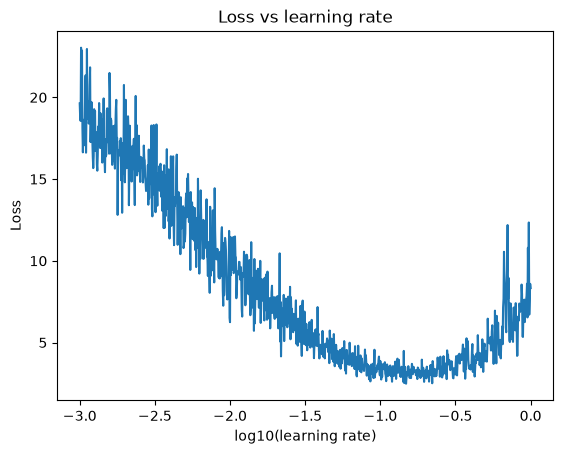

In [336]:
plt.plot(lri, lossi)  # loss is lowest around -1 (lr ~ 0.1) and blows up as the rate approaches 1
plt.xlabel('log10(learning rate)')
plt.ylabel('Loss')
plt.title('Loss vs learning rate');

### Training

Fresh weights again, then 10,000 steps of minibatch gradient descent with a fixed learning rate.

In [337]:
block_size = 3
embedding_dim = 2
parameters = init_params(seed=2147483647, neurons=100, embedding_dim=embedding_dim, block_size=block_size)  # fresh weights

C, W1, b1, W2, b2 = parameters
g = torch.Generator().manual_seed(2147483647)  # for the minibatch sampling

for i in range(10000):
    # minibatch of 32 random examples
    ix = torch.randint(0, X.shape[0], (32,), generator=g)

    # forward pass
    emb = C[X[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)  # (32, 100) hidden activations
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Y[ix])  # same loss as the manual version above, but faster and numerically stable

    # backward pass
    for p in parameters:
        p.grad = None  # reset gradients, otherwise they accumulate
    loss.backward()

    # update
    # NOTE: 0.7 is well past the valley of the plot above (~0.1). It happens to work for this 100-neuron model,
    # but it diverges for the larger 300-neuron model further down.
    lr = 0.7
    for p in parameters:
        p.data += -lr * p.grad

print(loss.item())  # loss on the last minibatch (noisy, since a batch is only 32 examples)

2.3818678855895996


In [338]:
# Loss on the entire dataset
# NOTE: this is the loss on the same data we trained on, so it can't tell us how well the model generalizes
emb = C[X]
h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)  # (228146, 100)
logits = h @ W2 + b2  # (228146, 27)
loss = F.cross_entropy(logits, Y)
loss.item()

2.4437530040740967

## A proper train / dev / test split

So far the loss was measured on the same data the model trained on, which can't tell us how well it generalizes. We split the names (not the individual examples) into three sets:

- **train (80%)** is used to fit the parameters.
- **dev (10%)** is used to compare settings such as the learning rate and the number of neurons.
- **test (10%)** is used **once**, at the very end, for the final number. Looking at it repeatedly while tuning would leak information from it into our choices.

In [339]:
shuffled = words.copy()  # shuffle a copy, so re-running this cell always gives the same split
random.seed(42)
random.shuffle(shuffled)
n1 = int(0.8 * len(shuffled))  # first 80% is train
n2 = int(0.9 * len(shuffled))  # next 10% is dev, the remaining 10% is test

Xtr, Ytr = build_dataset(shuffled[:n1])  # train
Xdev, Ydev = build_dataset(shuffled[n1:n2])  # dev / validation
Xte, Yte = build_dataset(shuffled[n2:])  # test

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


### A bigger model (300 hidden neurons)

Trained on the train split only. The learning rate has to be chosen with care: `0.7` worked for the 100-neuron model but makes this larger one diverge, so we start near the valley of the learning-rate plot (`0.1`) and drop to `0.01` for the last third of the steps, once the loss plateaus.

In [349]:
block_size = 3
embedding_dim = 10
parameters = init_params(seed=2147483647, neurons=200, embedding_dim=embedding_dim, block_size=block_size)  # fresh weights  # fresh weights, 300 hidden neurons
C, W1, b1, W2, b2 = parameters
g = torch.Generator().manual_seed(2147483647)  # for the minibatch sampling
sum(p.nelement() for p in parameters)  # total number of parameters

11897

In [350]:
# NOTE: continues from the current weights. Re-run the cell above first to start from scratch.
lossi = []

for i in range(30000):
    # minibatch of 32 random examples from the TRAIN set
    ix = torch.randint(0, Xtr.shape[0], (32,), generator=g)

    # forward pass
    emb = C[Xtr[ix]]  # (32, 3, 2)
    h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)  # (32, 300) hidden activations
    logits = h @ W2 + b2  # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix])

    # backward pass
    for p in parameters:
        p.grad = None  # reset gradients, otherwise they accumulate
    loss.backward()

    # update
    lr = 0.1 if i < 20000 else 0.01  # learning rate decay: 0.1 first, then 0.01 once the loss plateaus
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    lossi.append(loss.log10().item())

print(loss.item())  # loss on the last minibatch (noisy, since a batch is only 32 examples)

2.2569327354431152


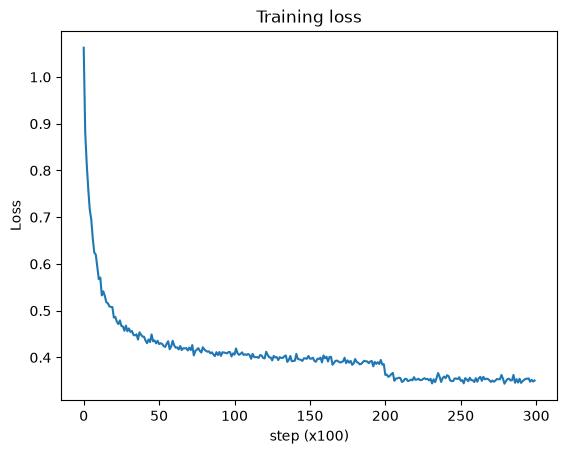

In [351]:
# The loss of a single 32-example batch is very noisy, so plot the average over every 100 steps
plt.plot(torch.tensor(lossi).view(-1, 100).mean(1))
plt.xlabel('step (x100)')
plt.ylabel('Loss')
plt.title('Training loss');

In [352]:
@torch.no_grad()
def split_loss(X, Y):
    emb = C[X]
    h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)
    logits = h @ W2 + b2
    return F.cross_entropy(logits, Y).item()

# Compare train and dev loss: similar values mean no overfitting yet, a large gap would mean overfitting
print(f"train loss: {split_loss(Xtr, Ytr):.4f}")
print(f"dev loss:   {split_loss(Xdev, Ydev):.4f}")

train loss: 2.2588
dev loss:   2.2808


### Final evaluation on the test set

Run this **once**, after all tuning on the dev set is finished.

In [353]:
print(f"test loss:  {split_loss(Xte, Yte):.4f}")

test loss:  2.2796


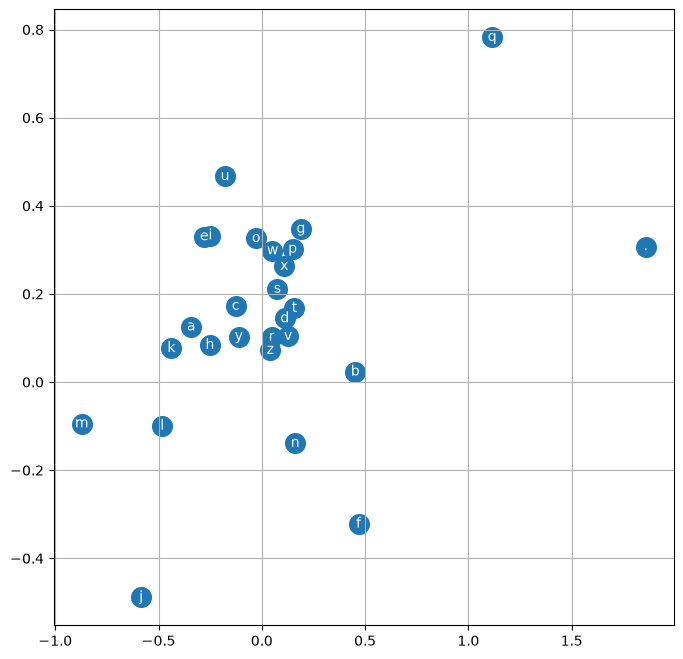

In [354]:
### Visualizing out embeddings in a 2D scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], color='white', fontsize=10, ha='center', va='center')
plt.grid('minor')

### Sampling from the model

In [355]:
g = torch.Generator().manual_seed(2147483647)  # for reproducibility

for _ in range(20):
    out = []
    context = [0] * block_size  # start with '...'
    while True:
        emb = C[torch.tensor([context])]  # (1, 3, 2)
        h = torch.tanh(emb.view(-1, block_size * embedding_dim) @ W1 + b1)  # (1, 300)
        logits = h @ W2 + b2  # (1, 27)
        counts = logits.exp()  # unnormalized probabilities
        probs = counts / counts.sum(1, keepdim=True)  # normalize to get probabilities
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()  # sample
        context = context[1:] + [ix]  # crop and append
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

dex.
maleah.
makila.
kayda.
kolimitta.
nolla.
kakanda.
samiyaulytahrigon.
shickiellaho.
keyten.
jena.
mar.
sade.
eniaviyn.
ratlse.
huciden.
tahlys.
dasdra.
anwil.
pyaw.
